# Titanic: Logistic Regression

Train Logistic Regression, evaluate survival predictions, and save the results. Run cells from top to bottom. The other model notebook uses exactly the same preparation and passenger split.

## 1. Imports and paths

In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, log_loss,
                             confusion_matrix, ConfusionMatrixDisplay)

ROOT = Path.cwd()
if not (ROOT / "data" / "data_preparation.py").is_file():
    ROOT = ROOT.parent  # supports a kernel started in models/
sys.path.insert(0, str(ROOT))
from data.data_preparation import load_data, prepare_data

OUTPUT = ROOT / "data" / "output"
GRAPHS = OUTPUT / "graphs"
GRAPHS.mkdir(parents=True, exist_ok=True)

## 2. Inspect and prepare data

`data/data_preparation.py` loads the original input and the fixed split, fills missing values using training medians/modes, encodes training categories, and scales numeric features using training statistics only.

In [2]:
frame = load_data()
print("Input shape:", frame.shape)
print("Missing values:\n", frame.isna().sum())
print("Duplicate rows:", frame.duplicated().sum())
print("Survival counts:\n", frame.Survived.value_counts())
X_train, X_test, y_train, y_test = prepare_data()
print("Training records:", len(X_train), "| Test records:", len(X_test))
print("Prepared columns:", X_train.columns.tolist())

Input shape: (891, 12)
Missing values:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
Duplicate rows: 0
Survival counts:
 Survived
0    549
1    342
Name: count, dtype: int64
Training records: 712 | Test records: 179
Prepared columns: ['Age', 'SibSp', 'Parch', 'Fare', 'Pclass_2', 'Pclass_3', 'Sex_male', 'Embarked_Q', 'Embarked_S']


## 3. Train the model

Logistic Regression estimates survival probability using a sigmoid of a weighted feature sum. It assumes linear log-odds. max_iter=1000 gives the default model enough iterations to converge.

In [3]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model_name = 'Logistic Regression'
file_stem = 'logistic_regression'
model.fit(X_train, y_train)
print(model_name, "training complete")

Logistic Regression training complete


## 4. Evaluate on test records

Survival is class 1. Precision, recall and F1 refer to survivors. ROC-AUC and log-loss use survival probabilities; predictions use threshold 0.5.

In [4]:
probability = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
prediction = (probability >= 0.5).astype(int)
scores = {
    "Accuracy": accuracy_score(y_test, prediction),
    "Precision": precision_score(y_test, prediction, zero_division=0),
    "Recall": recall_score(y_test, prediction, zero_division=0),
    "F1": f1_score(y_test, prediction, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, probability),
    "Log-loss": log_loss(y_test, np.column_stack([1-probability, probability]), labels=[0, 1]),
}
matrix = confusion_matrix(y_test, prediction, labels=[0, 1])
print(pd.Series(scores).round(4).to_string())
majority = y_train.mode().iloc[0]
baseline_accuracy = accuracy_score(y_test, np.full(len(y_test), majority))
print(f"Majority-class baseline accuracy: {baseline_accuracy:.4f}")

Accuracy     0.8045
Precision    0.7538
Recall       0.7206
F1           0.7368
ROC-AUC      0.8650
Log-loss     0.4342
Majority-class baseline accuracy: 0.6201


## 5. Plot the confusion matrix

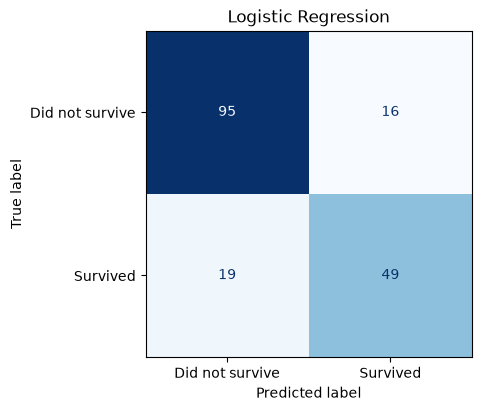

In [5]:
fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
ConfusionMatrixDisplay(matrix, display_labels=["Did not survive", "Survived"]).plot(
    ax=ax, colorbar=False, cmap="Blues")
ax.set_title(model_name)
fig.savefig(GRAPHS / f"{file_stem}_confusion_matrix.png", dpi=150)
plt.show()
plt.close(fig)

## 6. Update the shared results

Each notebook replaces only its own result. Run both notebooks after any change to the preparation or models.

In [6]:
# Preserve the other notebook's result when updating the shared report.
metrics_path = OUTPUT / "metrics.json"
saved = json.loads(metrics_path.read_text()) if metrics_path.exists() else {}
saved[model_name] = {
    "metrics": {key: float(value) for key, value in scores.items()},
    "confusion_matrix": matrix.tolist(),
    "training_records": len(y_train), "test_records": len(y_test),
    "majority_baseline_accuracy": float(baseline_accuracy),
}
order = ["Naive Bayes", "Logistic Regression"]
saved = {name: saved[name] for name in order if name in saved}
metrics_path.write_text(json.dumps(saved, indent=2) + "\n")
lines = ["# Titanic model metrics", "",
         f"Training records: {len(y_train)}. Test records: {len(y_test)}. Positive class: survived (1).",
         "These are test results from models fitted on the training records.", "",
         "| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | Log-loss |",
         "| --- | ---: | ---: | ---: | ---: | ---: | ---: |"]
for name, result in saved.items():
    values = result["metrics"]
    lines.append("| " + name + " | " + " | ".join(f"{values[key]:.4f}" for key in scores) + " |")
lines += ["", f"Majority-class baseline accuracy: {baseline_accuracy:.4f}.", "",
          "## Confusion matrices", ""]
for name, result in saved.items():
    stem = "naive_bayes" if name == "Naive Bayes" else "logistic_regression"
    lines += [f"![{name} confusion matrix](graphs/{stem}_confusion_matrix.png)", ""]
lines += ["Rows are true labels; columns are predictions, ordered [0, 1].", "",
          "## Findings", ""]
if all(name in saved for name in order):
    nb = saved["Naive Bayes"]["metrics"]
    lr = saved["Logistic Regression"]["metrics"]
    lines += [f"Naive Bayes accuracy: {nb['Accuracy']:.2%}; Logistic Regression accuracy: {lr['Accuracy']:.2%}.",
              f"LR-minus-NB accuracy difference: {100 * (lr['Accuracy']-nb['Accuracy']):.2f} percentage points.",
              f"Survival recall: NB {nb['Recall']:.4f}, LR {lr['Recall']:.4f}.",
              f"Log-loss (lower is better): NB {nb['Log-loss']:.4f}, LR {lr['Log-loss']:.4f}.", ""]
else:
    lines += ["Run the other model notebook to complete the comparison.", ""]
lines += ["Both models use the same fixed records and training-only preparation. No parameter search or threshold tuning is used.",
          "The test partition was inspected during earlier development; this is a fixed comparison, not a new independent test.",
          "A single historical sample does not establish that one model is universally better.", ""]
(OUTPUT / "metrics.md").write_text("\n".join(lines), encoding="utf-8")
print("Updated data/output/metrics.md and metrics.json")

Updated data/output/metrics.md and metrics.json
